# 02 · Đồ thị giao dịch

Notebook dựng mạng giao dịch từ đầu ra của `01_eda.ipynb` và mô tả nó, **không đọc nhãn** `is_laundering`.

- Đỉnh = tài khoản, khóa `bank_id + "_" + account_id` (mã ngân hàng dạng số, khớp `HI-Small_accounts.csv`).
- Cạnh = giao dịch, có hướng từ người trả sang người nhận; thời điểm và số tiền (`usd_paid`, `usd_recv`) là thuộc tính của cạnh.
- Hai cách nhìn: **T**, đồ thị sự kiện (`graph_edges`, mỗi giao dịch một cạnh) và **R**, đồ thị quan hệ (`directed_pairs`, mỗi cặp gửi → nhận một cạnh). *Tìm cấu trúc trong R, kiểm tra thời gian trong T.*

| Mục | Nội dung | Đầu ra chính |
|---|---|---|
| 1–3 | Đọc đầu vào, đánh chỉ số đỉnh, dựng T và R | |
| 4 | Kích thước đồ thị, mọi định dạng và ACH | `graph_summary.csv` |
| 5 | Degree | `graph_degree_summary.csv` |
| 6 | Thành phần liên thông | `graph_components.csv` |
| 7 | Đọc đồ thị: các bước biến đổi, phân phối degree, top hub, kích thước SCC, hình hub và vòng | `graph_*.csv`, `graph_*.png` |
| 8 | Đồ thị ACH và B3 cho RQ1 | |
| 9 | Góc nhìn một ngân hàng cho RQ3 | |
| 10 | Xuất đỉnh và cạnh | `graph_nodes.parquet`, `graph_edges.parquet` |

## 1. Chọn dữ liệu đầu vào

In [1]:
import json
import os
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

EDGE_REL = Path("data") / "processed" / "hi_small_graph_transactions.parquet"


def find_project_root():
    """HI_SMALL_ROOT nếu đã đặt; nếu không, tìm thư mục chứa đầu ra của notebook 01."""
    if os.environ.get("HI_SMALL_ROOT"):
        return Path(os.environ["HI_SMALL_ROOT"]).expanduser()
    here = Path.cwd()
    candidates = [Path("/kaggle/working"), here, here.parent,
                  here / "IBM_HI_Small_EDA", here.parent / "IBM_HI_Small_EDA"]
    for folder in candidates:
        if (folder / EDGE_REL).is_file():
            return folder
    raise FileNotFoundError(
        f"Không tìm thấy {EDGE_REL}. Chạy 01_eda.ipynb trước, "
        "hoặc đặt biến môi trường HI_SMALL_ROOT trỏ tới thư mục dự án.")


PROJECT_ROOT = find_project_root().resolve()
EDGE_FILE = PROJECT_ROOT / EDGE_REL
TAB_DIR = PROJECT_ROOT / "reports" / "tables"
FIG_DIR = PROJECT_ROOT / "reports" / "figures"
FX_FILE = TAB_DIR / "fx_rates.csv"
PERIOD_FILE = TAB_DIR / "analysis_period.json"
SCALE_FILE = TAB_DIR / "eda_scale.csv"
# Không bắt buộc: chỉ dùng để ghi loại chủ thể cho bảng top hub (mục 7.3).
ACCOUNTS_FILE = (Path(os.environ["HI_SMALL_ACCOUNTS"]).expanduser() if os.environ.get("HI_SMALL_ACCOUNTS")
                 else next((f / "HI-Small_accounts.csv" for f in (PROJECT_ROOT / "data" / "raw", PROJECT_ROOT, PROJECT_ROOT.parent)
                            if (f / "HI-Small_accounts.csv").is_file()), PROJECT_ROOT / "HI-Small_accounts.csv"))
FIG_DIR.mkdir(parents=True, exist_ok=True)
print(f"Thư mục dự án: {PROJECT_ROOT}")


def save_fig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    print(f"Đã ghi reports/figures/{name}.png")


for f in (EDGE_FILE, PERIOD_FILE, FX_FILE):
    if not f.is_file():
        raise FileNotFoundError(f"Thiếu {f}. Chạy 01_eda.ipynb trước.")

if "db" in globals():
    db.close()
db = duckdb.connect()
db.execute("SET threads = 4")
# Giới hạn RAM của DuckDB; phần vượt mức được ghi tạm ra đĩa thay vì làm sập kernel.
DUCKDB_TMP = PROJECT_ROOT / "data" / "duckdb_tmp"
DUCKDB_TMP.mkdir(parents=True, exist_ok=True)
db.execute(f"SET memory_limit = '{os.environ.get('HI_SMALL_DUCKDB_MEMORY', '2GB')}'")
db.execute(f"SET temp_directory = '{DUCKDB_TMP.as_posix()}'")
source = db.read_parquet(str(EDGE_FILE))
graph_input_columns = (
    "transaction_id", "timestamp", "src", "dst",
    "from_bank", "from_acct", "to_bank", "to_acct", "from_bank_id", "to_bank_id",
    "amt_paid", "pay_ccy", "amt_received", "recv_ccy", "payment_format",
)
missing = sorted(set(graph_input_columns) - set(source.columns))
if missing:
    raise ValueError(f"Tập giao dịch thiếu cột {missing}. Chạy lại 01_eda.ipynb.")
source_types = dict(zip(source.columns, source.types))
if any(str(source_types[c]) != "VARCHAR" for c in ("src", "dst", "from_bank", "from_acct", "to_bank", "to_acct")):
    raise ValueError("Mã ngân hàng và số tài khoản phải ở dạng chuỗi. Chạy lại 01_eda.ipynb.")
source.project(", ".join(graph_input_columns)).create_view("graph_transactions")
print(f"Đầu vào: {EDGE_FILE}")

period = json.loads(PERIOD_FILE.read_text(encoding="utf-8"))
print("Kỳ phân tích:", {k: period[k] for k in ("main_start", "dev_end", "main_end", "data_end")})

# Tỷ giá ước lượng trong notebook 01: mỗi tiền tệ một giá trị USD/đơn vị.
fx_rates = pd.read_csv(FX_FILE, dtype={"currency": str})
if not {"currency", "usd_per_unit"} <= set(fx_rates.columns):
    raise ValueError("fx_rates.csv phải có cột currency và usd_per_unit.")
fx_rates["usd_per_unit"] = pd.to_numeric(fx_rates["usd_per_unit"], errors="raise")
if (fx_rates["currency"].isna().any() or not fx_rates["currency"].is_unique
        or not (np.isfinite(fx_rates["usd_per_unit"]) & fx_rates["usd_per_unit"].gt(0)).all()):
    raise ValueError("Mỗi tiền tệ cần đúng một tỷ giá USD dương.")
db.register("graph_fx_rates", fx_rates[["currency", "usd_per_unit"]])
missing_currencies = db.execute("""
    SELECT DISTINCT c FROM (
        SELECT pay_ccy AS c FROM graph_transactions UNION SELECT recv_ccy FROM graph_transactions
    ) t LEFT JOIN graph_fx_rates fx ON t.c = fx.currency
    WHERE fx.currency IS NULL ORDER BY c
""").fetchall()
if missing_currencies:
    raise ValueError(f"Thiếu tỷ giá USD cho: {[c for c, in missing_currencies]}")
print(f"Tỷ giá USD: {FX_FILE}")

Thư mục dự án: D:\KLTN
Đầu vào: D:\KLTN\data\processed\hi_small_graph_transactions.parquet
Kỳ phân tích: {'main_start': '2022-09-01 00:00:00', 'dev_end': '2022-09-06 13:00:00', 'main_end': '2022-09-11 00:00:00', 'data_end': '2022-09-18 16:19:00'}
Tỷ giá USD: D:\KLTN\reports\tables\fx_rates.csv


## 2. Kiểm tra đầu vào và đánh chỉ số đỉnh

Một đỉnh là một tài khoản trong một ngân hàng, `account_key = bank_id + "_" + account_id`, với `bank_id` là mã ngân hàng **dạng số** (bỏ số 0 đầu). Cùng một ngân hàng có thể được viết `010` hoặc `10` trong file gốc; khóa số gộp chúng lại và khớp với cột `Bank ID` của `HI-Small_accounts.csv`. Mã chuỗi gốc vẫn còn trong `from_bank`/`to_bank` của cạnh để đối chiếu.

`node_id` lấy theo thứ tự chữ của `account_key` (không theo thứ tự dòng, vì thứ tự dòng tương quan với nhãn) và dùng chung cho mọi phần đồ thị lọc. `transaction_id` giữ nguyên từ EDA.

In [2]:
edge_count, unique_ids, self_loops, invalid_rows, first_ts, last_ts = db.execute("""
    SELECT count(*), count(DISTINCT transaction_id),
           count(*) FILTER (WHERE src = dst),
           count(*) FILTER (
               WHERE transaction_id IS NULL OR timestamp IS NULL
                  OR src IS NULL OR dst IS NULL
                  OR from_bank_id IS NULL OR from_acct IS NULL
                  OR to_bank_id IS NULL OR to_acct IS NULL
                  OR src <> concat(CAST(from_bank_id AS VARCHAR), '_', from_acct)
                  OR dst <> concat(CAST(to_bank_id AS VARCHAR), '_', to_acct)
                  OR amt_paid IS NULL OR amt_received IS NULL
                  OR NOT isfinite(amt_paid) OR NOT isfinite(amt_received)
                  OR pay_ccy IS NULL OR recv_ccy IS NULL OR payment_format IS NULL
           ),
           min(timestamp), max(timestamp)
    FROM graph_transactions
""").fetchall()[0]

if edge_count == 0 or edge_count != unique_ids or self_loops or invalid_rows:
    raise ValueError(
        f"Check the cleaned EDA edge file: {edge_count:,} rows, {unique_ids:,} unique "
        f"transaction IDs, {self_loops:,} self-loops, {invalid_rows:,} invalid rows."
    )

db.execute("""
    CREATE OR REPLACE TEMP TABLE nodes AS
    SELECT CAST(row_number() OVER (ORDER BY account_key) - 1 AS INTEGER) AS node_id,
           account_key, bank_id, CAST(bank_id AS VARCHAR) AS bank_code, account_id
    FROM (
        SELECT src AS account_key, from_bank_id AS bank_id, from_acct AS account_id
        FROM graph_transactions
        UNION
        SELECT dst AS account_key, to_bank_id AS bank_id, to_acct AS account_id
        FROM graph_transactions
    )
""")
nodes = db.execute("SELECT * FROM nodes ORDER BY node_id").df()
if not nodes["account_key"].is_unique:
    raise ValueError("An account key maps to more than one bank/account pair.")
print(f"Đã đánh chỉ số {len(nodes):,} tài khoản cho {edge_count:,} giao dịch.")

Đã đánh chỉ số 422,734 tài khoản cho 4,487,124 giao dịch.


## 3. Dựng đồ thị sự kiện T và đồ thị quan hệ R

Từ file CSV đến đồ thị đi qua ba dạng biểu diễn (Needham & Hodler, 2019, Hình 2-2):

| Dạng | Là gì | Ở đâu |
|---|---|---|
| Giả đồ thị (*pseudograph*) | File CSV thô: mỗi dòng một cạnh, có cả self-loop | Đầu vào của `01_eda.ipynb` |
| Đa đồ thị (*multigraph*) = **đồ thị sự kiện T** | Bỏ self-loop và dòng trùng; mỗi giao dịch một cạnh, nhiều cạnh có thể nối cùng một cặp tài khoản | `graph_edges` |
| Đồ thị đơn (*simple graph*) = **đồ thị quan hệ R** | Mỗi cặp gửi → nhận chỉ một cạnh: ai **từng** trả cho ai | `directed_pairs` |

**Định nghĩa.** Gọi $T = (V, E, s, d, t, a)$, trong đó $V$ là tập tài khoản và $E$ là tập giao dịch sau tiền xử lý. Với mỗi cạnh $e \in E$: $s(e)$ là tài khoản gửi, $d(e)$ là tài khoản nhận, $t(e)$ là thời điểm giao dịch (chính xác tới phút) và $a(e)$ là số tiền. Nhiều cạnh có thể có cùng cặp $(s(e), d(e))$, kể cả cùng thời điểm; `transaction_id` định danh từng cạnh. Đồ thị quan hệ là $R = (V, E_R)$ với $E_R = \{(s(e), d(e)) : e \in E\}$.

**Ý tưởng thiết kế: tìm cấu trúc trong R, kiểm tra thời gian trong T.** R trả lời "ai từng trả cho ai", dùng để tính degree, SCC và liệt kê vòng ứng viên. T trả lời "ai trả cho ai, lúc nào, bao nhiêu", dùng để đếm đối tác trong cửa sổ thời gian (RQ1) và kiểm tra một vòng có đi đúng thứ tự thời gian hay không (RQ2).

Số tiền là **thuộc tính** của cạnh, không phải trọng số theo nghĩa chi phí hay khoảng cách: không dùng nó để tìm đường đi ngắn nhất. Mỗi cạnh mang hai số tiền quy USD theo tỷ giá trong `fx_rates.csv`:
- `usd_paid = amt_paid × usd_per_unit(pay_ccy)`: số tiền **rời** tài khoản gửi;
- `usd_recv = amt_received × usd_per_unit(recv_ccy)`: số tiền **đến** tài khoản nhận.

RQ1 không dùng số tiền (fan chỉ đếm đối tác phân biệt); RQ2 dùng `usd_paid` để mô tả số tiền dọc một vòng.

In [3]:
db.execute("""
    CREATE OR REPLACE TEMP VIEW graph_edges AS
    SELECT s.node_id AS source_id, d.node_id AS target_id,
           t.src, t.dst, t.from_bank, t.to_bank, t.from_bank_id, t.to_bank_id,
           t.transaction_id, t.timestamp, CAST(epoch(t.timestamp) AS BIGINT) AS timestamp_s,
           t.amt_paid, t.pay_ccy, t.amt_received, t.recv_ccy, t.payment_format,
           t.amt_paid * fxp.usd_per_unit AS usd_paid,
           t.amt_received * fxr.usd_per_unit AS usd_recv
    FROM graph_transactions t
    JOIN nodes s ON t.src = s.account_key
    JOIN nodes d ON t.dst = d.account_key
    JOIN graph_fx_rates fxp ON t.pay_ccy = fxp.currency
    JOIN graph_fx_rates fxr ON t.recv_ccy = fxr.currency
""")
built_edges, invalid_amounts = db.execute("""
    SELECT count(*), count(*) FILTER (WHERE NOT isfinite(usd_paid) OR NOT isfinite(usd_recv))
    FROM graph_edges
""").fetchone()
if built_edges != edge_count or invalid_amounts:
    raise ValueError("Mỗi giao dịch phải thành đúng một cạnh của T, với số tiền USD hữu hạn.")

db.execute("""
    CREATE OR REPLACE TEMP TABLE directed_pairs AS
    SELECT DISTINCT source_id, target_id FROM graph_edges
""")
print(f"T (graph_edges): {built_edges:,} cạnh. "
      f"R (directed_pairs): {db.execute('SELECT count(*) FROM directed_pairs').fetchone()[0]:,} cạnh.")

T (graph_edges): 4,487,124 cạnh. R (directed_pairs): 647,939 cạnh.


## 4. Kích thước đồ thị

`transactions` là số cạnh của T. `unique_directed_pairs` là số cạnh của R (cặp gửi → nhận phân biệt). `parallel_edge_count` = số giao dịch lặp lại một cặp đã có. Cột **ACH** tính trên đồ thị con chỉ gồm giao dịch ACH, là phạm vi chính của RQ1–RQ2. Bảng lưu ở `reports/tables/graph_summary.csv`.

In [4]:
ordered_pairs = db.execute("SELECT count(*) FROM directed_pairs").fetchone()[0]
db.execute("""
    CREATE OR REPLACE TEMP TABLE ach_pairs AS
    SELECT DISTINCT source_id, target_id FROM graph_edges WHERE payment_format = 'ACH'
""")
ach_edge_count, ach_pair_count, ach_node_count, ach_bank_count = db.execute("""
    SELECT (SELECT count(*) FROM graph_edges WHERE payment_format = 'ACH'),
           (SELECT count(*) FROM ach_pairs),
           (SELECT count(*) FROM (SELECT source_id FROM ach_pairs UNION SELECT target_id FROM ach_pairs)),
           (SELECT count(*) FROM (
                SELECT from_bank_id FROM graph_edges WHERE payment_format = 'ACH'
                UNION SELECT to_bank_id FROM graph_edges WHERE payment_format = 'ACH'))
""").fetchone()
bank_count = nodes["bank_id"].nunique()

graph_summary = pd.DataFrame([
    ("accounts", len(nodes), ach_node_count),
    ("banks", bank_count, ach_bank_count),
    ("transactions", built_edges, ach_edge_count),
    ("unique_directed_pairs", ordered_pairs, ach_pair_count),
    ("parallel_edge_count", built_edges - ordered_pairs, ach_edge_count - ach_pair_count),
], columns=["metric", "all_formats", "ACH"])
graph_summary["ACH_share_pct"] = (100 * graph_summary["ACH"] / graph_summary["all_formats"]).round(2)
display(graph_summary)
graph_summary.to_csv(TAB_DIR / "graph_summary.csv", index=False)
print(f"Thời gian: {first_ts} → {last_ts}")
print(f"Giao dịch lặp lại một cặp đã có: {(built_edges - ordered_pairs) / built_edges:.1%} (mọi định dạng), "
      f"{(ach_edge_count - ach_pair_count) / ach_edge_count:.1%} (ACH).")

,metric,all_formats,ACH,ACH_share_pct
0,accounts,422734,238922,56.52
1,banks,23378,16280,69.64
2,transactions,4487124,529446,11.80
3,unique_directed_pairs,647939,208522,32.18
4,parallel_edge_count,3839185,320924,8.36


Thời gian: 2022-09-01 00:00:00 → 2022-09-18 16:18:00
Giao dịch lặp lại một cặp đã có: 85.6% (mọi định dạng), 60.6% (ACH).


## 5. Thống kê degree

In-degree và out-degree = số **đối tác phân biệt** trên R (không đếm số giao dịch). Bậc theo từng hướng có thể bằng 0. Cột ACH chỉ tính trên tài khoản có ít nhất một giao dịch ACH. Degree ACH của cả kỳ chỉ để mô tả; B3 của RQ1 tính lại trong từng đoạn ở notebook 03.

In [5]:
pair_indices = db.execute("SELECT source_id, target_id FROM directed_pairs").fetchnumpy()
ach_pair_indices = db.execute("SELECT source_id, target_id FROM ach_pairs").fetchnumpy()
node_count = len(nodes)
assert (nodes["node_id"].to_numpy() == np.arange(node_count)).all()

in_all = np.bincount(pair_indices["target_id"], minlength=node_count)
out_all = np.bincount(pair_indices["source_id"], minlength=node_count)
in_ach = np.bincount(ach_pair_indices["target_id"], minlength=node_count)
out_ach = np.bincount(ach_pair_indices["source_id"], minlength=node_count)
is_ach_node = (in_ach + out_ach) > 0
degrees = pd.DataFrame({"in_degree": in_all, "out_degree": out_all,
                        "ach_in_degree": in_ach, "ach_out_degree": out_ach})

pct = [0.5, 0.9, 0.99]
degree_summary = pd.concat({
    "all_formats": pd.DataFrame({"in_degree": in_all, "out_degree": out_all}).describe(percentiles=pct),
    "ACH": pd.DataFrame({"in_degree": in_ach[is_ach_node],
                         "out_degree": out_ach[is_ach_node]}).describe(percentiles=pct),
}, axis=1).round(4)
display(degree_summary)
degree_summary.to_csv(TAB_DIR / "graph_degree_summary.csv")

all_formats                       ACH             
         in_degree   out_degree    in_degree   out_degree
count  422734.0000  422734.0000  238922.0000  238922.0000
mean        1.5327       1.5327       0.8728       0.8728
std         2.7180      26.7071       2.9189       0.7913
min         0.0000       0.0000       0.0000       0.0000
50%         1.0000       1.0000       0.0000       1.0000
90%         3.0000       3.0000       2.0000       2.0000
99%         7.0000      10.0000      10.0000       3.0000
max       545.0000   14230.0000      93.0000      17.0000

## 6. Thành phần liên thông (chuẩn bị cho RQ2)

Mỗi chu trình có hướng nằm gọn trong một thành phần liên thông mạnh (SCC), nên chỉ cần tìm chu trình trong các SCC có ít nhất **2** tài khoản. Không bỏ SCC 2 đỉnh: `HI-Small_Patterns.txt` có chu trình độ dài 2 (A→B→A), và độ dài chu trình trong file trải từ 2 đến 12.

Mỗi view chỉ tính trên **tài khoản có giao dịch trong view đó** (`accounts_considered`):
- **mọi định dạng, cả kỳ**: mô tả toàn mạng;
- **ACH, cả kỳ**: view mà RQ2 dùng;
- **ACH, dev** và **ACH, test**: đúng phạm vi mà notebook 04 liệt kê chu trình (các đoạn đọc từ `analysis_period.json`).

> Lưu ý: nếu tính SCC của ACH trên mọi tài khoản, mỗi tài khoản không có giao dịch ACH sẽ thành một SCC 1 đỉnh và tổng số thành phần tăng giả. Vì vậy mỗi view chỉ xét tài khoản có giao dịch trong view đó.

Ở bước áp dụng rule (notebook 04), duyệt ứng viên trên R rồi dùng các cạnh gốc trong T để kiểm tra từng bước chuyển tiền: timestamp phải tăng nghiêm ngặt theo chiều chu trình. Các giao dịch cùng phút là các cạnh riêng.

In [6]:
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components


def adjacency(pairs):
    return coo_matrix(
        (np.ones(len(pairs["source_id"]), dtype=np.int8), (pairs["source_id"], pairs["target_id"])),
        shape=(node_count, node_count),
    ).tocsr()


def components(pairs, mode):
    """Components over accounts that appear in `pairs`. Accounts outside the view get -1."""
    keep = np.zeros(node_count, dtype=bool)
    keep[pairs["source_id"]] = True
    keep[pairs["target_id"]] = True
    idx = np.flatnonzero(keep)
    topology = adjacency(pairs)[idx][:, idx]
    count, sub = connected_components(topology, directed=True, connection=mode)
    membership = np.full(node_count, -1, dtype=np.int64)
    membership[idx] = sub
    return len(idx), count, membership, np.bincount(sub, minlength=count)


def ach_pairs_between(start, end):
    return db.execute("""
        SELECT DISTINCT source_id, target_id FROM graph_edges
        WHERE payment_format = 'ACH' AND timestamp >= ?::TIMESTAMP AND timestamp < ?::TIMESTAMP
    """, [start, end]).fetchnumpy()


views = [
    ("all_formats", "cả kỳ", pair_indices),
    ("ACH", "cả kỳ", ach_pair_indices),
    ("ACH", "dev", ach_pairs_between(period["main_start"], period["dev_end"])),
    ("ACH", "test", ach_pairs_between(period["dev_end"], period["main_end"])),
]
component_rows, scc_sizes, scc_membership = [], {}, {}
for view, part, pairs in views:
    for mode in ("strong", "weak"):
        considered, count, membership, sizes = components(pairs, mode)
        if mode == "strong":
            scc_sizes[(view, part)] = sizes
            scc_membership[(view, part)] = membership
        component_rows.append({
            "view": view, "period": part, "connectivity": mode,
            "accounts_considered": considered,
            "components": count,
            "nontrivial_components": int(np.count_nonzero(sizes > 1)),
            "accounts_in_nontrivial": int(sizes[sizes > 1].sum()),
            "largest_component": int(sizes.max()) if len(sizes) else 0,
        })
component_summary = pd.DataFrame(component_rows)
display(component_summary)
component_summary.to_csv(TAB_DIR / "graph_components.csv", index=False)

,view,period,connectivity,accounts_considered,components,nontrivial_components,accounts_in_nontrivial,largest_component
0,all_formats,cả kỳ,strong,422734,402415,2928,23247,17075
1,all_formats,cả kỳ,weak,422734,21785,21785,422734,372089
2,ACH,cả kỳ,strong,238922,235452,3043,6513,25
3,ACH,cả kỳ,weak,238922,50331,50331,238922,23653
4,ACH,dev,strong,209931,208774,1070,2227,10
5,ACH,dev,weak,209931,53036,53036,209931,7307
6,ACH,test,strong,156284,155461,762,1585,12
7,ACH,test,weak,156284,45450,45450,156284,593


## 7. Đọc đồ thị

Mục này trả lời "đồ thị trông như thế nào" trước khi áp bất kỳ quy tắc nào. Không ô nào đọc nhãn. Mỗi ô in một dòng **Ý nghĩa** để dùng làm chú thích hình trong khóa luận.

| Mục | Nội dung | Dùng trong khóa luận | Đầu ra |
|---|---|---|---|
| 7.1 | Các bước biến đổi: từ file CSV đến T, R, đồ thị con ACH và vùng có thể có vòng | Phương pháp, phần dựng đồ thị | `graph_transformation_steps.csv` |
| 7.2 | Phân phối degree (log-log) | Vì sao đầu bảng degree là doanh nghiệp lớn (RQ1) | `graph_degree_ccdf.png` |
| 7.3 | Top-10 hub theo bậc vào và bậc ra, mọi định dạng và ACH: loại chủ thể, định dạng thanh toán, giao dịch trên mỗi đối tác | Minh họa hub (RQ1) | `graph_top_hubs.csv`, `graph_top_hubs.png` |
| 7.4 | Phân phối kích thước SCC | Vì sao vòng trong ACH hiếm và nổi bật (RQ2) | `graph_scc_sizes.csv`, `graph_scc_sizes.png` |
| 7.5 | Hình một hub và một vòng | Minh họa hai hình dạng của đề tài | `graph_hub_and_loop.png` |

### 7.1 Các bước biến đổi

Mỗi dòng là một bước, kèm số cạnh, số tài khoản và số ngân hàng còn lại. Dòng 0 đọc từ `eda_scale.csv` của notebook 01. Dòng cuối là các cặp ACH có hai đầu nằm cùng một SCC ≥ 2 tài khoản: vòng ACH chỉ có thể nằm trong vùng này.

In [7]:
ach_member = scc_membership[("ACH", "cả kỳ")]
ach_sizes = scc_sizes[("ACH", "cả kỳ")]
src_c = ach_member[ach_pair_indices["source_id"]]
dst_c = ach_member[ach_pair_indices["target_id"]]
in_cycle_zone = (src_c == dst_c) & (ach_sizes[src_c] >= 2)
cycle_zone_accounts = int(ach_sizes[ach_sizes >= 2].sum())

scale = pd.read_csv(SCALE_FILE).iloc[0] if SCALE_FILE.is_file() else None
na = pd.NA
transformation_steps = pd.DataFrame([
    (0, "File giao dịch gốc", "mỗi dòng CSV một giao dịch",
     scale["transactions"] if scale is not None else na,
     scale["accounts"] if scale is not None else na,
     scale["banks"] if scale is not None else na),
    (1, "T: đa đồ thị giao dịch", "bỏ self-loop và dòng trùng (notebook 01)", built_edges, len(nodes), bank_count),
    (2, "R: đồ thị cặp", "gộp các giao dịch cùng cặp gửi → nhận", ordered_pairs, len(nodes), na),
    (3, "T chỉ ACH", "giữ giao dịch payment_format = ACH", ach_edge_count, ach_node_count, ach_bank_count),
    (4, "R chỉ ACH", "gộp cặp trong đồ thị con ACH", ach_pair_count, ach_node_count, na),
    (5, "Vùng có thể có vòng (ACH)", "cặp có hai đầu cùng một SCC ≥ 2 tài khoản",
     int(in_cycle_zone.sum()), cycle_zone_accounts, na),
], columns=["bước", "đồ thị", "cách làm", "cạnh", "tài khoản", "ngân hàng"])
for col in ("cạnh", "tài khoản", "ngân hàng"):
    transformation_steps[col] = transformation_steps[col].astype("Int64")
display(transformation_steps)
transformation_steps.to_csv(TAB_DIR / "graph_transformation_steps.csv", index=False)
print(f"Ý nghĩa: {(built_edges - ordered_pairs) / built_edges:.1%} giao dịch lặp lại một cặp tài khoản đã có, "
      f"nên mạng có {ordered_pairs / 1e6:.2f} triệu quan hệ cho {built_edges / 1e6:.2f} triệu sự kiện: cần cả T lẫn R. "
      f"Vòng ACH chỉ có thể nằm trong {cycle_zone_accounts:,} tài khoản ({cycle_zone_accounts / ach_node_count:.1%} "
      f"tài khoản ACH) và {in_cycle_zone.mean():.2%} cặp ACH.")

,bước,đồ thị,cách làm,cạnh,tài khoản,ngân hàng
0,0,File giao dịch gốc,mỗi dòng CSV một giao dịch,5078345,515088,30470
1,1,T: đa đồ thị giao dịch,bỏ self-loop và dòng trùng (notebook 01),4487124,422734,23378
2,2,R: đồ thị cặp,gộp các giao dịch cùng cặp gửi → nhận,647939,422734,<NA>
3,3,T chỉ ACH,giữ giao dịch payment_format = ACH,529446,238922,16280
4,4,R chỉ ACH,gộp cặp trong đồ thị con ACH,208522,238922,<NA>
5,5,Vùng có thể có vòng (ACH),cặp có hai đầu cùng một SCC ≥ 2 tài khoản,7267,6513,<NA>


Ý nghĩa: 85.6% giao dịch lặp lại một cặp tài khoản đã có, nên mạng có 0.65 triệu quan hệ cho 4.49 triệu sự kiện: cần cả T lẫn R. Vòng ACH chỉ có thể nằm trong 6,513 tài khoản (2.7% tài khoản ACH) và 3.49% cặp ACH.


### 7.2 Phân phối degree

Trục tung là tỷ lệ tài khoản có bậc **≥ k** (hàm phân phối bù, CCDF), cả hai trục theo thang log. Đường gần thẳng và kéo dài sang phải nghĩa là đuôi dày: phần lớn tài khoản có rất ít đối tác, một số ít có hàng trăm đến hàng nghìn.

Đã ghi reports/figures/graph_degree_ccdf.png


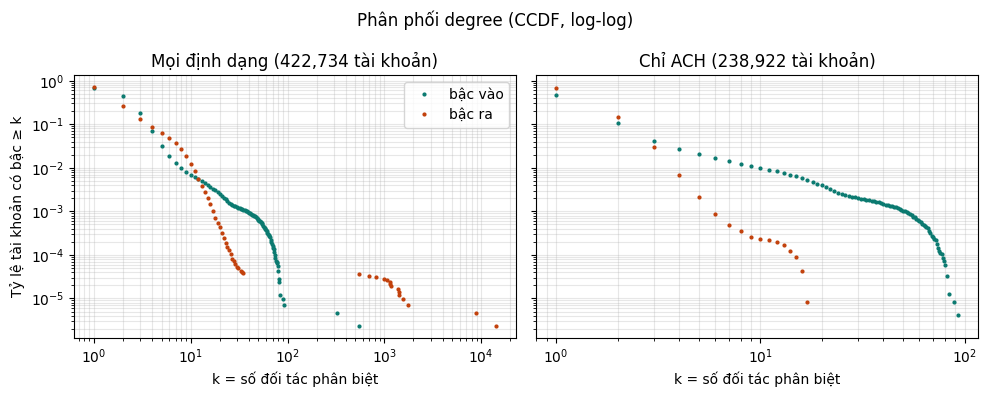

mọi định dạng: trung vị bậc vào 1, bậc ra 1; lớn nhất bậc vào 545, bậc ra 14,230; 43.3% tài khoản có nhiều nhất 1 đối tác mỗi hướng.
ACH: trung vị bậc vào 0, bậc ra 1; lớn nhất bậc vào 93, bậc ra 17; 76.1% tài khoản có nhiều nhất 1 đối tác mỗi hướng.
Ý nghĩa: phần lớn tài khoản chỉ có vài đối tác, một số ít có hàng trăm đến hàng nghìn (đuôi dày, cấu trúc trung tâm–nan hoa); vì vậy đầu mọi bảng xếp hạng degree là các chủ thể giao dịch rất nhiều. Trong ACH, bậc ra dừng ở 17 còn bậc vào lên tới 93.


In [8]:
COLORS = {"in": "#0B7A70", "out": "#C2410C"}
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
panels = [("Mọi định dạng", in_all, out_all, np.ones(node_count, dtype=bool)),
          ("Chỉ ACH", in_ach, out_ach, is_ach_node)]
for ax, (title, d_in, d_out, mask) in zip(axes, panels):
    total = int(mask.sum())
    for values, label, color in ((d_in[mask], "bậc vào", COLORS["in"]),
                                 (d_out[mask], "bậc ra", COLORS["out"])):
        k, counts = np.unique(values[values > 0], return_counts=True)
        ccdf = counts[::-1].cumsum()[::-1] / total
        ax.loglog(k, ccdf, ".", ms=4, color=color, label=label)
    ax.set_title(f"{title} ({total:,} tài khoản)")
    ax.set_xlabel("k = số đối tác phân biệt")
    ax.grid(alpha=0.3, which="both")
axes[0].set_ylabel("Tỷ lệ tài khoản có bậc ≥ k")
axes[0].legend()
fig.suptitle("Phân phối degree (CCDF, log-log)")
fig.tight_layout()
save_fig(fig, "graph_degree_ccdf")
plt.show()

for name, d_in, d_out, mask in (("mọi định dạng", in_all, out_all, None), ("ACH", in_ach, out_ach, is_ach_node)):
    a = d_in if mask is None else d_in[mask]
    b = d_out if mask is None else d_out[mask]
    print(f"{name}: trung vị bậc vào {np.median(a):.0f}, bậc ra {np.median(b):.0f}; "
          f"lớn nhất bậc vào {a.max():,}, bậc ra {b.max():,}; "
          f"{np.mean(np.maximum(a, b) <= 1):.1%} tài khoản có nhiều nhất 1 đối tác mỗi hướng.")
print("Ý nghĩa: phần lớn tài khoản chỉ có vài đối tác, một số ít có hàng trăm đến hàng nghìn (đuôi dày, cấu trúc "
      "trung tâm–nan hoa); vì vậy đầu mọi bảng xếp hạng degree là các chủ thể giao dịch rất nhiều. "
      f"Trong ACH, bậc ra dừng ở {out_ach.max()} còn bậc vào lên tới {in_ach.max()}.")

### 7.3 Top-10 hub

Mười tài khoản có nhiều đối tác phân biệt nhất theo từng hướng, trên R của **mọi định dạng** và của **ACH** (cả kỳ; đồng hạng phá theo `node_id`). Mỗi dòng ghi:
- `entity_type`: loại chủ thể, lấy từ `HI-Small_accounts.csv` theo cùng cách với notebook 03 (để trống nếu không có file);
- `degree`: số đối tác phân biệt theo hướng đó; `n_tx`: số giao dịch theo hướng đó; `tx_per_partner = n_tx / degree`;
- `formats`: các định dạng thanh toán của các giao dịch theo hướng đó (mọi định dạng), kèm tỷ lệ.

Bảng chỉ mô tả cấu trúc, không ghép nhãn và không dùng để chọn gì.

all_formats · bậc vào (nhận từ nhiều đối tác):


,rank,account_key,entity_type,degree,n_tx,tx_per_partner,formats
0,1,70_100428660,Sole Proprietorship,545,1084,1.99,Cash 100%
1,2,70_1004286A8,Partnership,328,653,1.99,Cash 100%
2,3,21611_8051A3FA0,Corporation,93,94,1.01,ACH 100%
3,4,4726_808FAF7C0,Partnership,89,89,1.00,ACH 100%
4,5,14277_80B847A90,Corporation,84,84,1.00,ACH 100%
5,6,13145_80640B300,Sole Proprietorship,82,82,1.00,ACH 100%
6,7,213005_8050E2560,Partnership,82,82,1.00,ACH 100%
7,8,2915_801AF5660,Sole Proprietorship,82,82,1.00,ACH 100%
8,9,39678_80F523260,Corporation,82,82,1.00,ACH 100%
9,10,7042_80640FE10,Partnership,82,82,1.00,ACH 100%


all_formats · bậc ra (chuyển cho nhiều đối tác):


,rank,account_key,entity_type,degree,n_tx,tx_per_partner,formats
10,1,70_100428660,Sole Proprietorship,14230,168672,11.85,"Cheque 49%, Credit Card 31%, Cash 20%"
11,2,70_1004286A8,Partnership,8846,103018,11.65,"Cheque 49%, Credit Card 31%, Cash 20%"
12,3,70_100428978,Sole Proprietorship,1776,20497,11.54,"Cheque 49%, Credit Card 30%, Cash 21%"
13,4,70_1004286F0,Partnership,1575,18663,11.85,"Cheque 50%, Credit Card 30%, Cash 21%"
14,5,70_1004289C0,Sole Proprietorship,1432,16794,11.73,"Cheque 49%, Credit Card 30%, Cash 21%"
15,6,70_100428780,Sole Proprietorship,1421,17264,12.15,"Cheque 48%, Credit Card 31%, Cash 21%"
16,7,70_100428810,Sole Proprietorship,1394,16426,11.78,"Cheque 49%, Credit Card 30%, Cash 21%"
17,8,70_1004287C8,Corporation,1182,14174,11.99,"Cheque 49%, Credit Card 32%, Cash 20%"
18,9,70_100428A51,Country,1147,13073,11.40,Bitcoin 100%
19,10,70_100428738,Corporation,1136,13756,12.11,"Cheque 48%, Credit Card 31%, Cash 21%"


ACH · bậc vào (nhận từ nhiều đối tác):


,rank,account_key,entity_type,degree,n_tx,tx_per_partner,formats
20,1,21611_8051A3FA0,Corporation,93,94,1.01,ACH 100%
21,2,4726_808FAF7C0,Partnership,89,89,1.00,ACH 100%
22,3,14277_80B847A90,Corporation,84,84,1.00,ACH 100%
23,4,13145_80640B300,Sole Proprietorship,82,82,1.00,ACH 100%
24,5,213005_8050E2560,Partnership,82,82,1.00,ACH 100%
25,6,2915_801AF5660,Sole Proprietorship,82,82,1.00,ACH 100%
26,7,39678_80F523260,Corporation,82,82,1.00,ACH 100%
27,8,7042_80640FE10,Partnership,82,82,1.00,ACH 100%
28,9,1292_8003946A0,Partnership,80,80,1.00,ACH 100%
29,10,12_800326F20,Corporation,80,80,1.00,ACH 100%


ACH · bậc ra (chuyển cho nhiều đối tác):


,rank,account_key,entity_type,degree,n_tx,tx_per_partner,formats
30,1,7548_8040AE4F0,Partnership,17,17,1.00,ACH 100%
31,2,9679_80452D470,Sole Proprietorship,17,26,1.53,"ACH 46%, Cash 18%, Cheque 18%"
32,3,1267_8007C7660,Corporation,16,16,1.00,ACH 100%
33,4,210431_809BFD6B0,Corporation,16,16,1.00,"ACH 80%, Cheque 10%, Credit Card 10%"
34,5,21174_800737690,Sole Proprietorship,16,16,1.00,ACH 100%
35,6,213952_808338D40,Partnership,16,16,1.00,"ACH 43%, Credit Card 19%, Cheque 19%"
36,7,214615_8075AC7C0,Partnership,16,25,1.56,"ACH 71%, Cheque 29%"
37,8,214749_805DB7F20,Partnership,16,16,1.00,"Cheque 40%, ACH 37%, Wire 23%"
38,9,21611_8051B3BF0,Corporation,16,17,1.06,ACH 100%
39,10,21749_80154AAF0,Partnership,16,17,1.06,ACH 100%


Đã ghi reports/figures/graph_top_hubs.png


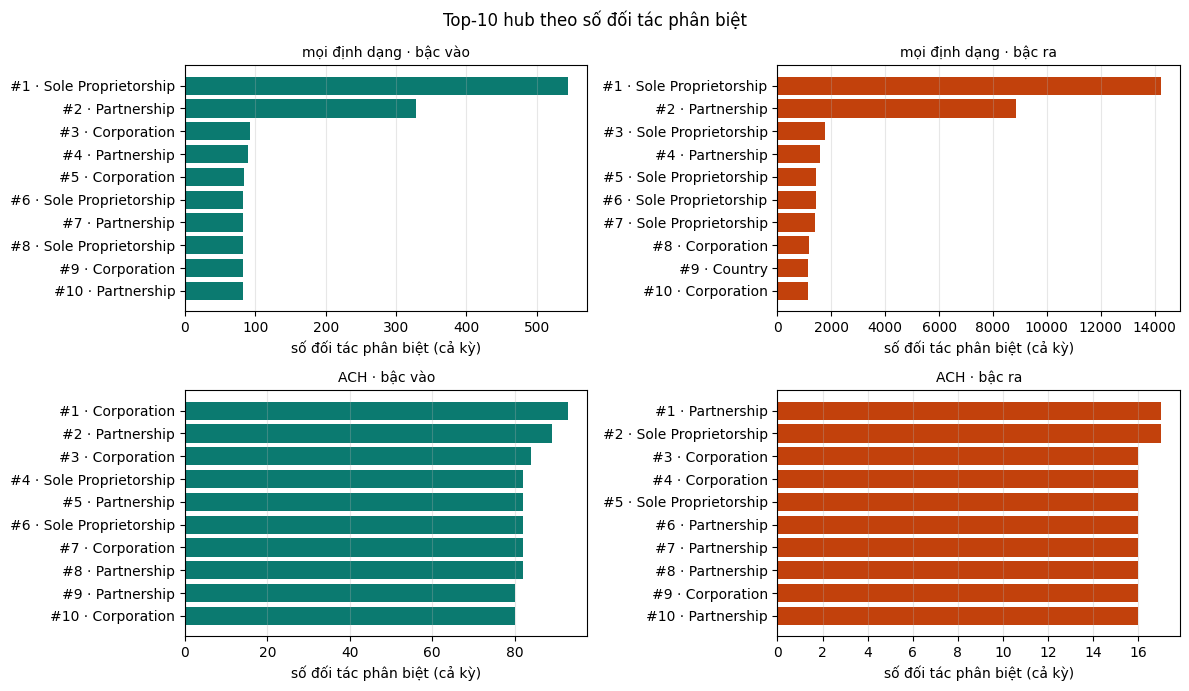

Ý nghĩa: 27/40 hub đầu bảng là công ty hoặc công ty hợp danh, giao dịch với rất nhiều đối tác theo kiểu kinh doanh thông thường (nhận một lần từ mỗi khách, hoặc trả định kỳ nhiều lần cho mỗi người nhận). mọi định dạng, bậc vào: trung vị 83 đối tác, 1.0 giao dịch mỗi đối tác, chủ yếu ACH; mọi định dạng, bậc ra: trung vị 1,426 đối tác, 11.8 giao dịch mỗi đối tác, chủ yếu Cheque; ACH, bậc vào: trung vị 82 đối tác, 1.0 giao dịch mỗi đối tác, chủ yếu ACH; ACH, bậc ra: trung vị 16 đối tác, 1.0 giao dịch mỗi đối tác, chủ yếu ACH.


In [9]:
if ACCOUNTS_FILE.is_file():
    entity = db.execute("""
        SELECT TRY_CAST("Bank ID" AS BIGINT) AS bank_id, CAST("Account Number" AS VARCHAR) AS account_id,
               coalesce(nullif(regexp_extract(CAST("Entity Name" AS VARCHAR), '^(.*?) #', 1), ''),
                        'Unknown') AS entity_type
        FROM read_csv(?, header = true, all_varchar = true)
    """, [str(ACCOUNTS_FILE)]).df().drop_duplicates(["bank_id", "account_id"])
    entity_type = (nodes[["node_id", "bank_id", "account_id"]]
                   .merge(entity, on=["bank_id", "account_id"], how="left")
                   .sort_values("node_id")["entity_type"].fillna("Unknown").to_numpy())
else:
    print(f"Không thấy {ACCOUNTS_FILE}; bỏ trống cột loại chủ thể. Đặt HI_SMALL_ACCOUNTS để điền cột này.")
    entity_type = np.full(node_count, "", dtype=object)

degree_views = {("all_formats", "in"): in_all, ("all_formats", "out"): out_all,
                ("ACH", "in"): in_ach, ("ACH", "out"): out_ach}
rows = []
for (view, direction), deg in degree_views.items():
    order = np.lexsort((np.arange(node_count), -deg))[:10]
    rows += [{"view": view, "direction": direction, "rank": r, "node_id": int(n), "degree": int(deg[n])}
             for r, n in enumerate(order, start=1)]
top_hubs = pd.DataFrame(rows)
hub_ids = top_hubs.node_id.unique().tolist()
by_format = db.execute("""
    SELECT node_id, direction, payment_format, count(*) AS n FROM (
        SELECT source_id AS node_id, 'out' AS direction, payment_format FROM graph_edges
        WHERE list_contains(?::INTEGER[], source_id)
        UNION ALL
        SELECT target_id, 'in', payment_format FROM graph_edges
        WHERE list_contains(?::INTEGER[], target_id)
    ) GROUP BY ALL
""", [hub_ids, hub_ids]).df()


def hub_details(r):
    # Dùng r["..."] thay cho r.view: Series có hàm .view() trùng tên ở một số phiên bản pandas.
    part = by_format[(by_format.node_id == r["node_id"]) & (by_format.direction == r["direction"])]
    n_tx = int(part["n"].sum() if r["view"] == "all_formats" else part.loc[part.payment_format == "ACH", "n"].sum())
    shares = part.set_index("payment_format")["n"].sort_values(ascending=False) / max(part["n"].sum(), 1)
    formats = ", ".join(f"{f} {s:.0%}" for f, s in shares.head(3).items())
    return pd.Series({"n_tx": n_tx, "tx_per_partner": n_tx / r["degree"] if r["degree"] else np.nan, "formats": formats})


top_hubs = pd.concat([top_hubs, top_hubs.apply(hub_details, axis=1)], axis=1)
top_hubs.insert(4, "account_key", nodes.account_key.to_numpy()[top_hubs.node_id])
top_hubs.insert(5, "entity_type", entity_type[top_hubs.node_id])
top_hubs.to_csv(TAB_DIR / "graph_top_hubs.csv", index=False)

show_cols = ["rank", "account_key", "entity_type", "degree", "n_tx", "tx_per_partner", "formats"]
for view in ("all_formats", "ACH"):
    for direction in ("in", "out"):
        print(f"{view} · {'bậc vào (nhận từ nhiều đối tác)' if direction == 'in' else 'bậc ra (chuyển cho nhiều đối tác)'}:")
        display(top_hubs[(top_hubs.view == view) & (top_hubs.direction == direction)][show_cols].round(2))

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, ((view, direction), _) in zip(axes.ravel(), degree_views.items()):
    part = top_hubs[(top_hubs.view == view) & (top_hubs.direction == direction)].iloc[::-1]
    labels = [f"#{r} · {e}" if e else f"#{r}" for r, e in zip(part["rank"], part["entity_type"])]
    ax.barh(labels, part["degree"], color=COLORS[direction])
    ax.set_title(f"{'mọi định dạng' if view == 'all_formats' else 'ACH'} · "
                 f"{'bậc vào' if direction == 'in' else 'bậc ra'}", fontsize=10)
    ax.set_xlabel("số đối tác phân biệt (cả kỳ)")
    ax.grid(alpha=0.3, axis="x")
fig.suptitle("Top-10 hub theo số đối tác phân biệt")
fig.tight_layout()
save_fig(fig, "graph_top_hubs")
plt.show()

types = top_hubs.entity_type.value_counts()
summary = top_hubs.groupby(["view", "direction"], sort=False).agg(
    degree=("degree", "median"), tx_per_partner=("tx_per_partner", "median"),
    formats=("formats", lambda x: pd.Series([f.split(" ")[0] for f in x if f]).mode().iat[0] if any(x) else "?"))
lines = [f"{'mọi định dạng' if v == 'all_formats' else 'ACH'}, {'bậc vào' if d == 'in' else 'bậc ra'}: trung vị "
         f"{r.degree:,.0f} đối tác, {r.tx_per_partner:.1f} giao dịch mỗi đối tác, chủ yếu {r.formats}"
         for (v, d), r in summary.iterrows()]
print(f"Ý nghĩa: {types.get('Corporation', 0) + types.get('Partnership', 0)}/{len(top_hubs)} hub đầu bảng là công ty "
      "hoặc công ty hợp danh, giao dịch với rất nhiều đối tác theo kiểu kinh doanh thông thường (nhận một lần từ mỗi "
      "khách, hoặc trả định kỳ nhiều lần cho mỗi người nhận). " + "; ".join(lines) + ".")

### 7.4 Kích thước SCC

Số SCC theo kích thước, chỉ tính SCC ≥ 2 tài khoản. So sánh đồ thị con ACH (cả kỳ, dev, test) với đồ thị mọi định dạng: nếu mọi định dạng có một SCC khổng lồ thì vòng ở đó phần lớn là nhiễu nền; nếu SCC của ACH đều nhỏ thì vòng ACH hiếm và nổi bật.

Đã ghi reports/figures/graph_scc_sizes.png


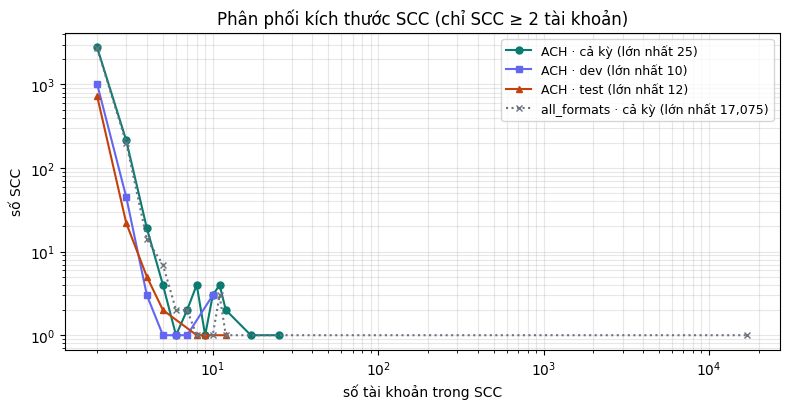

n_scc  largest
view        period                
ACH         cả kỳ    3043       25
            dev      1070       10
            test      762       12
all_formats cả kỳ    2928    17075

Ý nghĩa: SCC lớn nhất của mọi định dạng có 17,075 tài khoản, của ACH chỉ 25; trong ACH vòng hiếm và nổi bật, còn trong mọi định dạng vòng phần lớn là nhiễu nền.


In [10]:
scc_size_rows = []
fig, ax = plt.subplots(figsize=(8, 4.2))
styles = {("ACH", "cả kỳ"): ("#0B7A70", "o"), ("ACH", "dev"): ("#6366F1", "s"),
          ("ACH", "test"): ("#C2410C", "^"), ("all_formats", "cả kỳ"): ("#6B7280", "x")}
for key, (color, marker) in styles.items():
    sizes = scc_sizes[key]
    sizes = sizes[sizes >= 2]
    if not len(sizes):
        continue
    k, counts = np.unique(sizes, return_counts=True)
    scc_size_rows += [{"view": key[0], "period": key[1], "scc_size": int(a), "n_scc": int(b)}
                for a, b in zip(k, counts)]
    ax.plot(k, counts, marker=marker, ls="-" if key[0] == "ACH" else ":", color=color, ms=5,
            label=f"{key[0]} · {key[1]} (lớn nhất {sizes.max():,})")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("số tài khoản trong SCC")
ax.set_ylabel("số SCC")
ax.grid(alpha=0.3, which="both")
ax.legend(fontsize=9)
ax.set_title("Phân phối kích thước SCC (chỉ SCC ≥ 2 tài khoản)")
fig.tight_layout()
save_fig(fig, "graph_scc_sizes")
plt.show()

scc_size_table = pd.DataFrame(scc_size_rows)
scc_size_table.to_csv(TAB_DIR / "graph_scc_sizes.csv", index=False)
display(scc_size_table.groupby(["view", "period"]).agg(n_scc=("n_scc", "sum"), largest=("scc_size", "max")))
print(f"Ý nghĩa: SCC lớn nhất của mọi định dạng có {scc_sizes[('all_formats', 'cả kỳ')].max():,} tài khoản, của ACH chỉ "
      f"{scc_sizes[('ACH', 'cả kỳ')].max()}; trong ACH vòng hiếm và nổi bật, còn trong mọi định dạng vòng phần lớn là nhiễu nền.")

### 7.5 Một hub và một vòng

- **(a) Hub:** tài khoản ACH đứng đầu bảng 7.3 theo bậc ra, cùng các đối tác ACH của nó (vẽ tối đa 24 người nhận và 12 người gửi, ưu tiên đối tác có nhiều giao dịch).
- **(b) Vòng nhỏ:** SCC ACH 3 tài khoản đầu tiên theo `node_id` (nếu không có, lấy SCC nhỏ nhất ≥ 3). Các cung được đánh số theo thời điểm giao dịch đầu tiên của cặp; chú thích dưới hình ghi số giao dịch và thời điểm. Đây chỉ là **vòng tĩnh** trên R; việc kiểm tra thứ tự thời gian thuộc notebook 04.
- **(c) SCC ACH lớn nhất** của cả kỳ: vùng tập trung nhiều vòng nhất.

Hình chọn theo quy tắc cố định ở trên, không theo nhãn.

Đã ghi reports/figures/graph_hub_and_loop.png


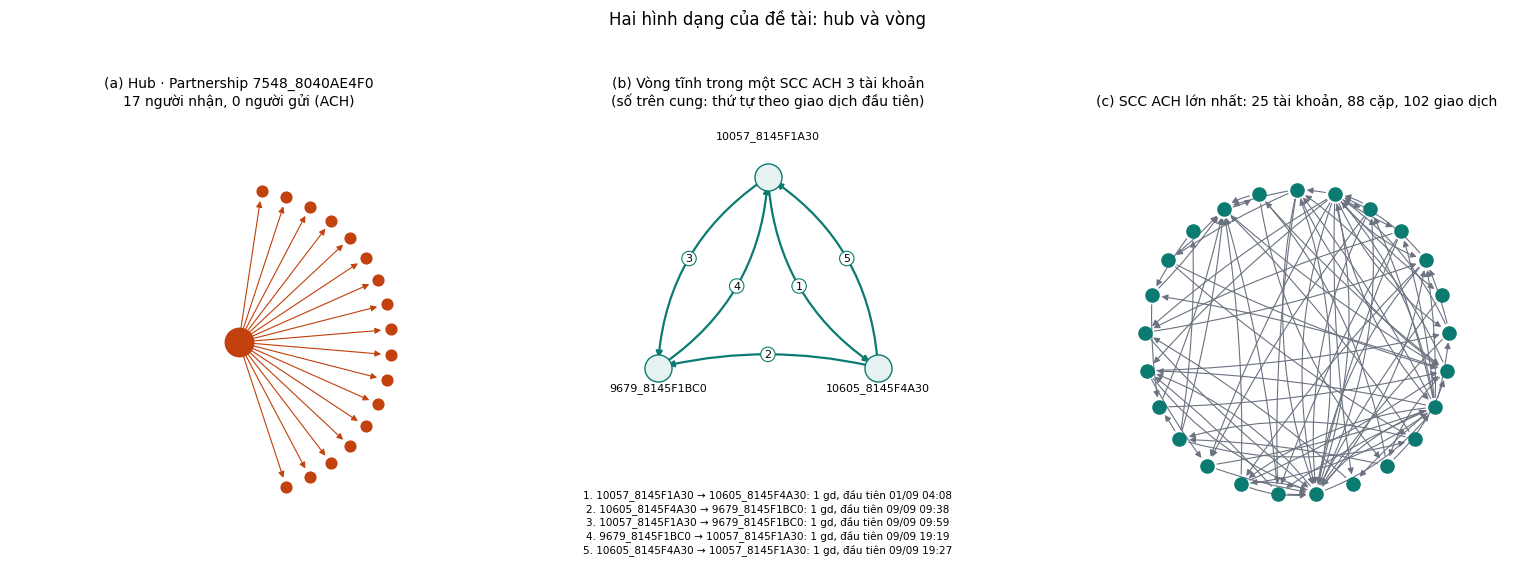

Ý nghĩa: (a) một tài khoản ACH chuyển tiền cho 17 người nhận khác nhau; (b) một nhóm tài khoản chuyển qua lại tạo vòng, và thứ tự thời gian của các cung quyết định tiền có thật sự quay về hay không; (c) vùng có nhiều vòng nhất của ACH cũng chỉ gồm 25 tài khoản.


In [11]:
from matplotlib.patches import FancyArrowPatch


def arrow(ax, p, q, color, lw=1.0, rad=0.0):
    ax.add_patch(FancyArrowPatch(p, q, arrowstyle="-|>", mutation_scale=9, color=color, lw=lw,
                                 shrinkA=7, shrinkB=7, connectionstyle=f"arc3,rad={rad}"))


def pair_stats(ids):
    return db.execute("""
        SELECT source_id, target_id, count(*) AS n, min(timestamp) AS first_ts
        FROM graph_edges
        WHERE payment_format = 'ACH' AND list_contains(?::INTEGER[], source_id)
          AND list_contains(?::INTEGER[], target_id)
        GROUP BY ALL
    """, [list(map(int, ids)), list(map(int, ids))]).df()


def circle(n, start=np.pi / 2, span=2 * np.pi):
    angles = start - span * np.arange(n) / max(n, 1)
    return np.c_[np.cos(angles), np.sin(angles)]


fig, axes = plt.subplots(1, 3, figsize=(16, 5.6))

# (a) hub
hub = int(top_hubs[(top_hubs.view == "ACH") & (top_hubs.direction == "out")].iloc[0]["node_id"])
nbr = db.execute("""
    SELECT CASE WHEN source_id = ? THEN 'out' ELSE 'in' END AS side,
           CASE WHEN source_id = ? THEN target_id ELSE source_id END AS other, count(*) AS n
    FROM graph_edges
    WHERE payment_format = 'ACH' AND (source_id = ? OR target_id = ?) AND source_id <> target_id
    GROUP BY ALL ORDER BY n DESC, other
""", [hub, hub, hub, hub]).df()
ax = axes[0]
ax.scatter([0], [0], s=420, color=COLORS["out"], zorder=3)
for side, cap, start, color in (("out", 24, np.pi / 2 - 0.15, COLORS["out"]),
                                ("in", 12, -np.pi / 2 - 0.15, COLORS["in"])):
    part = nbr[nbr.side == side]
    shown = part.head(cap)
    pos = circle(len(shown), start=start, span=np.pi - 0.3) * 1.0
    for (x, y), n in zip(pos, shown["n"]):
        ax.scatter([x], [y], s=60, color=color, zorder=3)
        if side == "out":
            arrow(ax, (0, 0), (x, y), color, lw=0.6 + 0.3 * np.log1p(n))
        else:
            arrow(ax, (x, y), (0, 0), color, lw=0.6 + 0.3 * np.log1p(n))
    if len(part) > cap:
        ax.text(0.95 if side == "out" else -0.95, -1.25 if side == "out" else 1.2,
                f"+{len(part) - cap:,} {'người nhận' if side == 'out' else 'người gửi'} khác",
                ha="center", fontsize=9, color=color)
ax.set_title(f"(a) Hub · {entity_type[hub] or 'tài khoản'} {nodes.account_key.iloc[hub]}\n"
             f"{int(out_ach[hub]):,} người nhận, {int(in_ach[hub]):,} người gửi (ACH)", fontsize=10)

# (b) small loop
sizes_all = scc_sizes[("ACH", "cả kỳ")]
cands = np.flatnonzero(sizes_all == 3)
if not len(cands):
    bigger = np.flatnonzero(sizes_all >= 3)
    cands = bigger[sizes_all[bigger] == sizes_all[bigger].min()] if len(bigger) else np.array([], dtype=int)
ax = axes[1]
if len(cands):
    first_by_node = min(cands, key=lambda c: np.flatnonzero(ach_member == c).min())
    loop_nodes = np.flatnonzero(ach_member == first_by_node)
    pos = dict(zip(loop_nodes, circle(len(loop_nodes))))
    stats = pair_stats(loop_nodes).sort_values(["first_ts", "source_id"]).reset_index(drop=True)
    pairs_set = set(zip(stats.source_id, stats.target_id))
    legend_lines = []
    for n_edge, r in enumerate(stats.itertuples(), start=1):
        p_, q_ = np.asarray(pos[r.source_id], float), np.asarray(pos[r.target_id], float)
        rad = 0.25 if (r.target_id, r.source_id) in pairs_set else 0.12
        arrow(ax, p_, q_, "#0B7A70", lw=1.6, rad=rad)
        # Số thứ tự đặt ở giữa cung cong (arc3: điểm điều khiển lệch rad × (dy, −dx)).
        perp = np.array([(q_ - p_)[1], -(q_ - p_)[0]])
        ax.text(*((p_ + q_) / 2 + 0.5 * rad * perp), str(n_edge), ha="center", va="center", fontsize=8,
                bbox=dict(boxstyle="circle,pad=0.2", fc="white", ec="#0B7A70", lw=0.8), zorder=4)
        legend_lines.append(f"{n_edge}. {nodes.loc[r.source_id, 'account_key']} → "
                            f"{nodes.loc[r.target_id, 'account_key']}: {r.n} gd, "
                            f"đầu tiên {pd.Timestamp(r.first_ts):%d/%m %H:%M}")
    ax.text(0, -1.45, "\n".join(legend_lines), ha="center", va="top", fontsize=7.5)
    for nid, (x, y) in pos.items():
        ax.scatter([x], [y], s=380, color="#E6F2F1", edgecolor="#0B7A70", zorder=3)
        ax.text(x, y * 1.32, nodes.loc[nid, "account_key"], ha="center", va="center", fontsize=8)
    ax.set_title(f"(b) Vòng tĩnh trong một SCC ACH {len(loop_nodes)} tài khoản\n"
                 "(số trên cung: thứ tự theo giao dịch đầu tiên)", fontsize=10)
else:
    ax.text(0, 0, "Không có SCC ACH ≥ 3 tài khoản", ha="center")

# (c) largest ACH SCC
ax = axes[2]
big = int(np.argmax(sizes_all))
big_nodes = np.flatnonzero(ach_member == big)
pos = dict(zip(big_nodes, circle(len(big_nodes))))
big_stats = pair_stats(big_nodes)
big_set = set(zip(big_stats.source_id, big_stats.target_id))
for _, r in big_stats.iterrows():
    rad = 0.15 if (r.target_id, r.source_id) in big_set else 0.05
    arrow(ax, pos[r.source_id], pos[r.target_id], "#6B7280", lw=0.8, rad=rad)
xy = np.array(list(pos.values()))
ax.scatter(xy[:, 0], xy[:, 1], s=90, color="#0B7A70", zorder=3)
ax.set_title(f"(c) SCC ACH lớn nhất: {len(big_nodes)} tài khoản, {len(big_stats)} cặp, "
             f"{int(big_stats.n.sum()):,} giao dịch", fontsize=10)

for ax in axes:
    ax.set_aspect("equal")
    ax.set_xlim(-1.5, 1.5)
    ax.set_ylim(-2.1 if ax is axes[1] else -1.5, 1.5)
    ax.axis("off")
fig.suptitle("Hai hình dạng của đề tài: hub và vòng", fontsize=12, y=1.03)
fig.tight_layout()
save_fig(fig, "graph_hub_and_loop")
plt.show()
print(f"Ý nghĩa: (a) một tài khoản ACH chuyển tiền cho {out_ach[hub]} người nhận khác nhau; (b) một nhóm tài khoản "
      "chuyển qua lại tạo vòng, và thứ tự thời gian của các cung quyết định tiền có thật sự quay về hay không; "
      f"(c) vùng có nhiều vòng nhất của ACH cũng chỉ gồm {len(big_nodes)} tài khoản.")

## 8. Đồ thị ACH và đối chứng B3 cho RQ1 (Hubs)

`rq1_ach_edges` giữ từng giao dịch ACH thuộc **kỳ chính** đọc từ `analysis_period.json`, tức $[\mathrm{main\_start}, \mathrm{main\_end})$, không gồm đuôi cuối kỳ. Muốn mô tả toàn kỳ thì đặt `RQ1_PERIOD_START = RQ1_PERIOD_END = None`. Notebook 03 tự chia kỳ chính thành dev/test.

Tại thời điểm $t$, fan-in của tài khoản $v$ đếm số tài khoản gửi tới $v$ có ít nhất một giao dịch trong $[t-W,t]$. Fan-out đếm số tài khoản nhận từ $v$ theo cùng điều kiện. $W=24$ và $48$ giờ là cửa sổ chính; $96$ giờ là kiểm tra độ nhạy. Một đối tác chỉ đóng góp một đơn vị, bất kể số giao dịch hay số tiền. Hàm `rq1_window_counts()` minh họa phép đếm cho một tài khoản tại một thời điểm.

`rq1_b3_pairs` gộp các cặp gửi–nhận từ **chính kỳ ACH đó**. B3 là bậc theo số đối tác phân biệt trong cả kỳ, dùng để kiểm tra giá trị của cửa sổ thời gian ở cùng hướng, cùng tập tài khoản và cùng số cảnh báo.

In [12]:
RQ1_PERIOD_START = period["main_start"]   # None = from the first transaction
RQ1_PERIOD_END = period["main_end"]       # exclusive; None = to the last transaction

split_start = pd.Timestamp(RQ1_PERIOD_START) if RQ1_PERIOD_START is not None else None
split_end = pd.Timestamp(RQ1_PERIOD_END) if RQ1_PERIOD_END is not None else None
if any(pd.isna(value) or value.tzinfo is not None
       for value in (split_start, split_end) if value is not None):
    raise ValueError("Use valid, timezone-naive timestamps for the RQ1 period.")
if split_start is not None and split_end is not None and split_start >= split_end:
    raise ValueError("RQ1_PERIOD_START must precede RQ1_PERIOD_END.")

db.sql("""
    SELECT * FROM graph_edges
    WHERE payment_format = 'ACH'
      AND timestamp >= coalesce(?::TIMESTAMP, TIMESTAMP '-infinity')
      AND timestamp < coalesce(?::TIMESTAMP, TIMESTAMP 'infinity')
""", params=[split_start, split_end]).create_view("rq1_ach_edges", replace=True)
db.execute("""
    CREATE OR REPLACE TEMP VIEW rq1_b3_pairs AS
    SELECT DISTINCT source_id, target_id
    FROM rq1_ach_edges
""")

def rq1_window_counts(account_key, window_end, window_hours):
    """Count distinct ACH counterparties for one window within the RQ1 period."""
    if window_hours not in (24, 48, 96):
        raise ValueError("window_hours must be 24, 48 or 96.")
    end = pd.Timestamp(window_end)
    if pd.isna(end) or end.tzinfo is not None:
        raise ValueError("Use a valid, timezone-naive window_end.")
    if ((split_start is not None and end < split_start)
            or (split_end is not None and end >= split_end)):
        raise ValueError("window_end must lie in the RQ1 period.")
    start = end - pd.Timedelta(hours=window_hours)
    return db.sql("""
        SELECT count(DISTINCT source_id) FILTER (WHERE dst = ?) AS fan_in,
               count(DISTINCT target_id) FILTER (WHERE src = ?) AS fan_out
        FROM rq1_ach_edges
        WHERE timestamp BETWEEN ? AND ? AND (src = ? OR dst = ?)
    """, params=[account_key, account_key, start, end, account_key, account_key]).fetchall()[0]

ach_edges, ach_accounts, b3_pairs = db.execute("""
    WITH pairs AS (SELECT * FROM rq1_b3_pairs)
    SELECT (SELECT count(*) FROM rq1_ach_edges),
           (SELECT count(*) FROM (
               SELECT source_id AS node_id FROM pairs
               UNION
               SELECT target_id AS node_id FROM pairs
           )),
           (SELECT count(*) FROM pairs)
""").fetchall()[0]

print(f"Kỳ RQ1: [{split_start}, {split_end})")
print(f"ACH trong kỳ RQ1: {ach_edges:,} giao dịch; {ach_accounts:,} tài khoản.")
print(f"B3 của RQ1: {b3_pairs:,} cặp gửi → nhận phân biệt trong cùng kỳ ACH.")

Kỳ RQ1: [2022-09-01 00:00:00, 2022-09-11 00:00:00)
ACH trong kỳ RQ1: 528,731 giao dịch; 238,704 tài khoản.
B3 của RQ1: 207,899 cặp gửi → nhận phân biệt trong cùng kỳ ACH.


## 9. Góc nhìn một ngân hàng cho RQ3

RQ3 hỏi: một ngân hàng chỉ thấy giao dịch của khách hàng mình thì thấy trọn được bao nhiêu vòng. Giả định quan sát: một ngân hàng thấy mọi giao dịch có tài khoản gửi hoặc nhận thuộc ngân hàng đó. Một consortium gộp phạm vi quan sát của các ngân hàng thành viên. Mỗi giao dịch xuất hiện một lần ngay cả khi hai đầu cùng thuộc nhóm.

Dùng `bank_edge_view([70])` cho một ngân hàng hoặc `bank_edge_view([70, 10404])` cho một nhóm. Mã có thể là số hoặc chuỗi (`"070"` và `70` là một ngân hàng). Hàm trả về một DuckDB relation để lọc hoặc đếm tiếp.

In [13]:
def bank_edge_view(bank_codes):
    """Return each edge visible to at least one selected bank (codes compared as integers)."""
    codes = [bank_codes] if isinstance(bank_codes, (str, int, np.integer)) else list(bank_codes)
    try:
        ids = [int(str(code).strip()) for code in codes]
    except ValueError as exc:
        raise ValueError("Bank codes must be whole numbers, e.g. 70 or '070'.") from exc
    if not ids:
        raise ValueError("Pass at least one bank code.")
    return db.sql("""
        SELECT * FROM graph_edges
        WHERE list_contains(?::BIGINT[], from_bank_id)
           OR list_contains(?::BIGINT[], to_bank_id)
    """, params=[ids, ids])

## 10. Xuất đồ thị để dùng ở notebook khác

Các bảng DuckDB ở trên có hiệu lực trong kernel hiện tại. Nếu muốn notebook 03–04
đọc trực tiếp danh sách đỉnh và cạnh đã dựng, đặt `GRAPH_OUTPUT_DIR` thành một thư mục
trên máy. Giữ `None` khi chỉ cần xem kết quả trong notebook. Hai tệp Parquet xuất ra
chứa cấu trúc đồ thị và thuộc tính của giao dịch.

In [14]:
GRAPH_OUTPUT_DIR = PROJECT_ROOT / "data" / "processed" / "graph"
if GRAPH_OUTPUT_DIR is not None:
    graph_output_dir = Path(GRAPH_OUTPUT_DIR).expanduser().resolve()
    graph_output_dir.mkdir(parents=True, exist_ok=True)
    db.execute("COPY nodes TO ? (FORMAT PARQUET)", [str(graph_output_dir / "graph_nodes.parquet")])
    db.execute("COPY (SELECT * FROM graph_edges ORDER BY transaction_id) TO ? (FORMAT PARQUET)",
               [str(graph_output_dir / "graph_edges.parquet")])
    print(f"Đã ghi graph_nodes.parquet và graph_edges.parquet vào {graph_output_dir}")

Đã ghi graph_nodes.parquet và graph_edges.parquet vào D:\KLTN\data\processed\graph
